from https://medium.com/data-science/hands-on-bayesian-statistics-with-python-pymc3-arviz-499db9a59501

Probabilistic vs. Deterministic (frequentist)

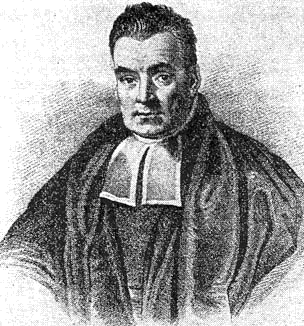

In [2]:
from scipy import stats
import arviz as az
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import seaborn as sns
import pandas as pd
from pytensor import shared

C:\Users\jmeek\anaconda3\envs\ghupload\Lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [3]:
url = "https://raw.githubusercontent.com/susanli2016/Machine-Learning-with-Python/master/data/renfe_small.csv"
df = pd.read_csv(url, index_col=0)

In [4]:
df.head(10)

,origin,destination,start_date,end_date,train_type,price,train_class,fare
insert_date,,,,,,,,
2019-04-22 08:00:25,MADRID,SEVILLA,2019-04-28 08:30:00,2019-04-28 11:14:00,ALVIA,NaN,Turista,Flexible
2019-04-22 10:03:24,MADRID,VALENCIA,2019-05-20 06:45:00,2019-05-20 08:38:00,AVE,21.95,Turista,Promo
2019-04-25 19:19:46,MADRID,SEVILLA,2019-05-29 06:20:00,2019-05-29 09:16:00,AV City,38.55,Turista,Promo
2019-04-24 06:21:57,SEVILLA,MADRID,2019-05-03 08:35:00,2019-05-03 15:26:00,LD-MD,34.35,Turista con enlace,Promo +
2019-04-19 21:13:55,VALENCIA,MADRID,2019-05-10 09:40:00,2019-05-10 11:20:00,AVE,45.30,Turista,Promo
2019-04-13 14:05:18,MADRID,BARCELONA,2019-04-15 19:30:00,2019-04-15 22:40:00,AVE,85.10,Turista,Promo
2019-04-17 19:18:39,BARCELONA,MADRID,2019-05-04 19:00:00,2019-05-04 22:00:00,AVE,98.00,Preferente,Promo
2019-05-09 03:06:08,MADRID,VALENCIA,2019-05-21 15:40:00,2019-05-21 17:22:00,AVE,33.65,Turista,Promo
2019-05-04 01:17:16,MADRID,BARCELONA,2019-05-27 07:15:00,2019-05-27 16:37:00,R. EXPRES,43.25,Turista,Adulto ida


In [5]:
df = df.dropna(subset=['price'])

<Axes: >

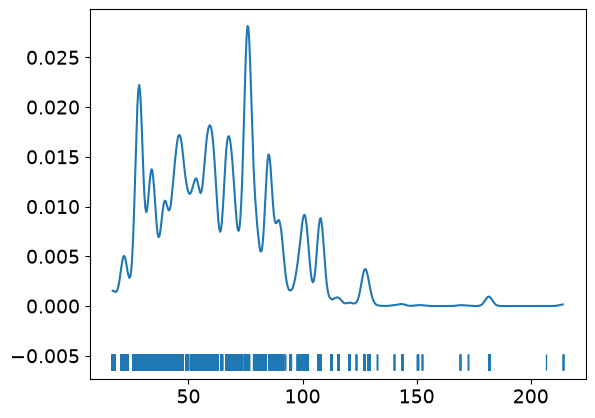

In [6]:
az.plot_kde(df['price'].values, rug=True)

In [7]:
#priors: mu = uniform 0 - 1000, sigma2 = halfnormal, sd = 20
with pm.Model() as model_g:
    mu = pm.Uniform('mu', lower = 0, upper = 1000)
    sigma2 = pm.HalfNormal('sigma2', sigma = 20)
    y = pm.Normal('y', mu=mu, sigma=sigma2, observed=df['price'].values)
    trace_g = pm.sample(1000, tune = 500)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma2]


Output()

Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 38 seconds.


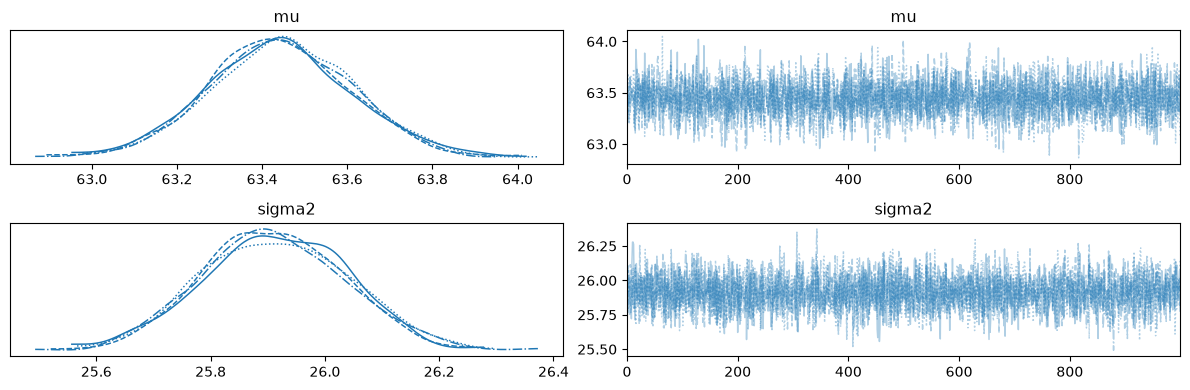

In [8]:
az.plot_trace(trace_g)
plt.tight_layout()

<Axes: xlabel='mu', ylabel='sigma2'>

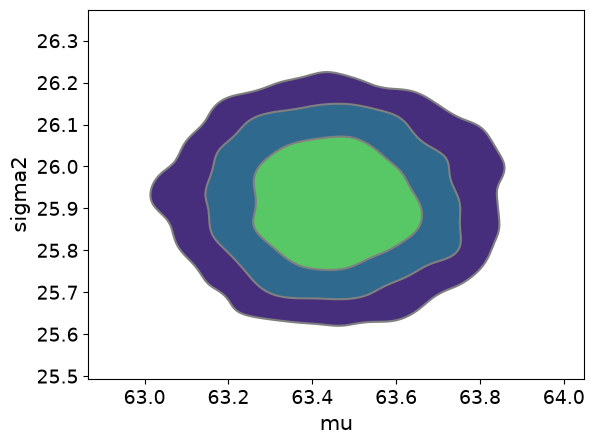

In [9]:
az.plot_pair(trace_g, kind='kde')

In [10]:
az.summary(trace_g)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu,63.444,0.168,63.142,63.772,0.003,0.003,4186.0,3160.0,1.0
sigma2,25.912,0.124,25.693,26.153,0.002,0.002,4170.0,2969.0,1.0


array([<Axes: title={'center': 'mu'}>, <Axes: title={'center': 'sigma2'}>],
      dtype=object)

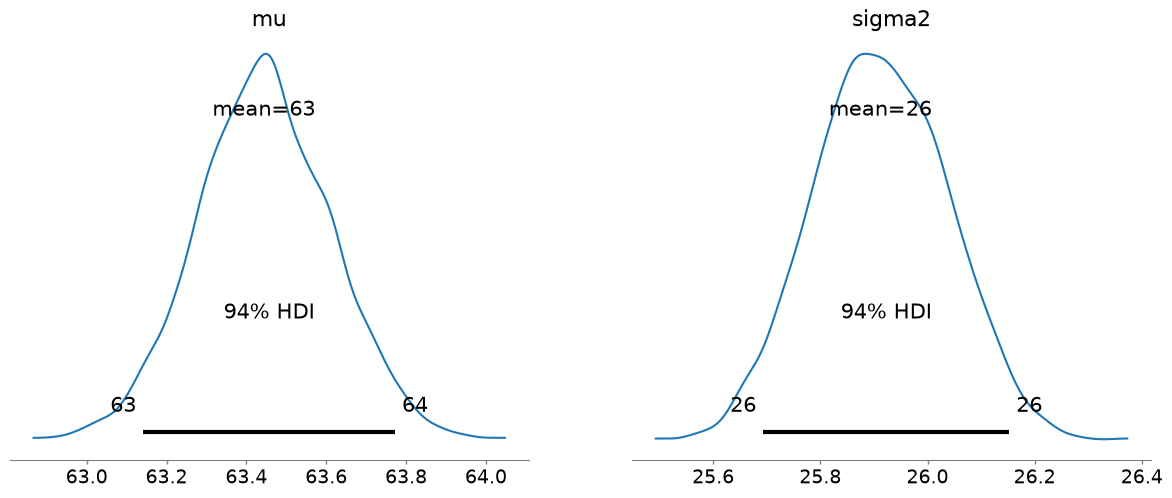

In [11]:
az.plot_posterior(trace_g)

In [12]:
pm.rhat(trace_g)

<xarray.Dataset> Size: 16B
Dimensions:  ()
Data variables:
    mu       float64 8B 1.001
    sigma2   float64 8B 1.001
Attributes:
    created_at:                 2026-11-26T19:04:19.375274+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.5
    sampling_time:              37.95813989639282
    tuning_steps:               500

### Posterior Predictive Checks

In [13]:
with model_g:
  posterior_predictive = pm.sample_posterior_predictive(
      trace_g,
      extend_inferencedata=True,
      random_seed=42,
  )

y_pp = posterior_predictive.posterior_predictive["y"]
print(y_pp.shape)

Sampling: [y]


Output()

(4, 1000, 22716)


Text(0.5, 1.0, 'Posterior Predictive of the Mean')

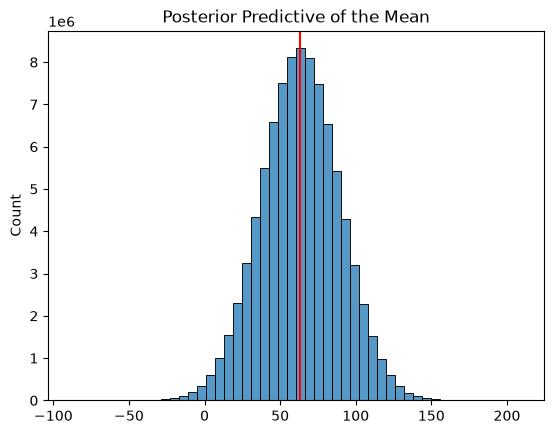

In [15]:
y_pp_flat = y_pp.to_numpy().ravel()
sns.histplot(x=y_pp_flat, bins=50)
plt.axvline(df.price.mean(), color='red')
plt.title("Posterior Predictive of the Mean")

In [16]:
price = df['price'].values
idx = pd.Categorical(df['fare'], categories=['Flexible', 'Promo', 'Promo +', 'Adulto ida', 'Mesa', 'Individual-Flexible']).codes
groups = len(np.unique(idx))

In [17]:
with pm.Model() as comparing_groups:
    mu = pm.Normal('mu', mu=0, sigma=20, shape=groups)
    sigma2 = pm.HalfNormal('sigma2', sigma=20, shape=groups)
    y = pm.Normal('y', mu=mu[idx], sigma=sigma2[idx], observed=price)

    trace_groups = pm.sample(5000, tune=500)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma2]


Output()

Sampling 4 chains for 500 tune and 5_000 draw iterations (2_000 + 20_000 draws total) took 197 seconds.


In [20]:
fares_gaussian = az.summary(trace_groups)
fares_gaussian

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu[0],82.047,0.385,81.324,82.760,0.002,0.003,27807.0,15525.0,1.0
mu[1],62.437,0.182,62.095,62.779,0.001,0.001,32193.0,15335.0,1.0
mu[2],37.230,0.215,36.827,37.627,0.001,0.002,34546.0,16025.0,1.0
mu[3],31.126,0.142,30.856,31.390,0.001,0.001,29575.0,14817.0,1.0
mu[4],46.041,20.687,7.834,85.910,0.150,0.136,18977.0,14978.0,1.0
mu[5],40.520,20.630,1.166,78.540,0.139,0.141,22229.0,15428.0,1.0
sigma2[0],26.251,0.271,25.726,26.747,0.002,0.002,28847.0,14842.0,1.0
sigma2[1],22.604,0.127,22.358,22.834,0.001,0.001,30674.0,15766.0,1.0
sigma2[2],5.618,0.153,5.346,5.918,0.001,0.001,33164.0,15206.0,1.0
sigma2[3],5.809,0.101,5.618,5.996,0.001,0.001,28984.0,15244.0,1.0


### Hierarchical Regression Model

In [26]:
def replace_fare(fare):

    if fare == 'Adulto ida':
        return 1
    elif fare == 'Promo +':
        return 2
    elif fare == 'Promo':
        return 3
    elif fare == 'Flexible':
        return 4
    elif fare == 'Individual-Flexible':
        return 5
    elif fare == 'Mesa':
        return 6

df['fare_encode'] = df['fare'].apply(lambda x: replace_fare(x))

trainTypeNames, trainTypeIdx = np.unique(
    df['train_type'].to_numpy(), return_inverse=True
)
df['train_type_encode'] = trainTypeIdx

nTrainTypes = len(trainTypeNames)

df[['train_type', 'price', 'fare_encode']].head()

,train_type,price,fare_encode
insert_date,,,
2019-04-22 10:03:24,AVE,21.95,3
2019-04-25 19:19:46,AV City,38.55,3
2019-04-24 06:21:57,LD-MD,34.35,2
2019-04-19 21:13:55,AVE,45.30,3
2019-04-13 14:05:18,AVE,85.10,3


In [36]:
with pm.Model() as hierarchical_model:
    #global parameters
    mu_tmp = pm.Normal('mu_tmp', mu=0, sigma=100)
    sigma2_tmp = pm.HalfNormal('sigma2_tmp', sigma=20)
    betaMu = pm.Normal('betaMu', mu=0, sigma=100)
    betaSigma2 = pm.HalfNormal('betaSigma2', sigma=20)

    #train type model parameters
    alpha_tmp = pm.Normal('alpha_tmp', mu=mu_tmp, sigma=sigma2_tmp, shape=nTrainTypes)
    beta = pm.Normal('beta', mu=betaMu, sigma=betaSigma2, shape = nTrainTypes)
    eps = pm.HalfCauchy('eps', beta=10)

    fare_est = alpha_tmp[trainTypeIdx] + beta[trainTypeIdx]*df.fare_encode.values

    #likelihood
    fare_likelihood = pm.Normal('fare_like', mu=fare_est, sigma=eps, observed=df.price)

with hierarchical_model:
    hierarchical_trace = pm.sample(2000, tune = 500)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_tmp, sigma2_tmp, betaMu, betaSigma2, alpha_tmp, beta, eps]


Output()

Sampling 4 chains for 500 tune and 2_000 draw iterations (2_000 + 8_000 draws total) took 646 seconds.


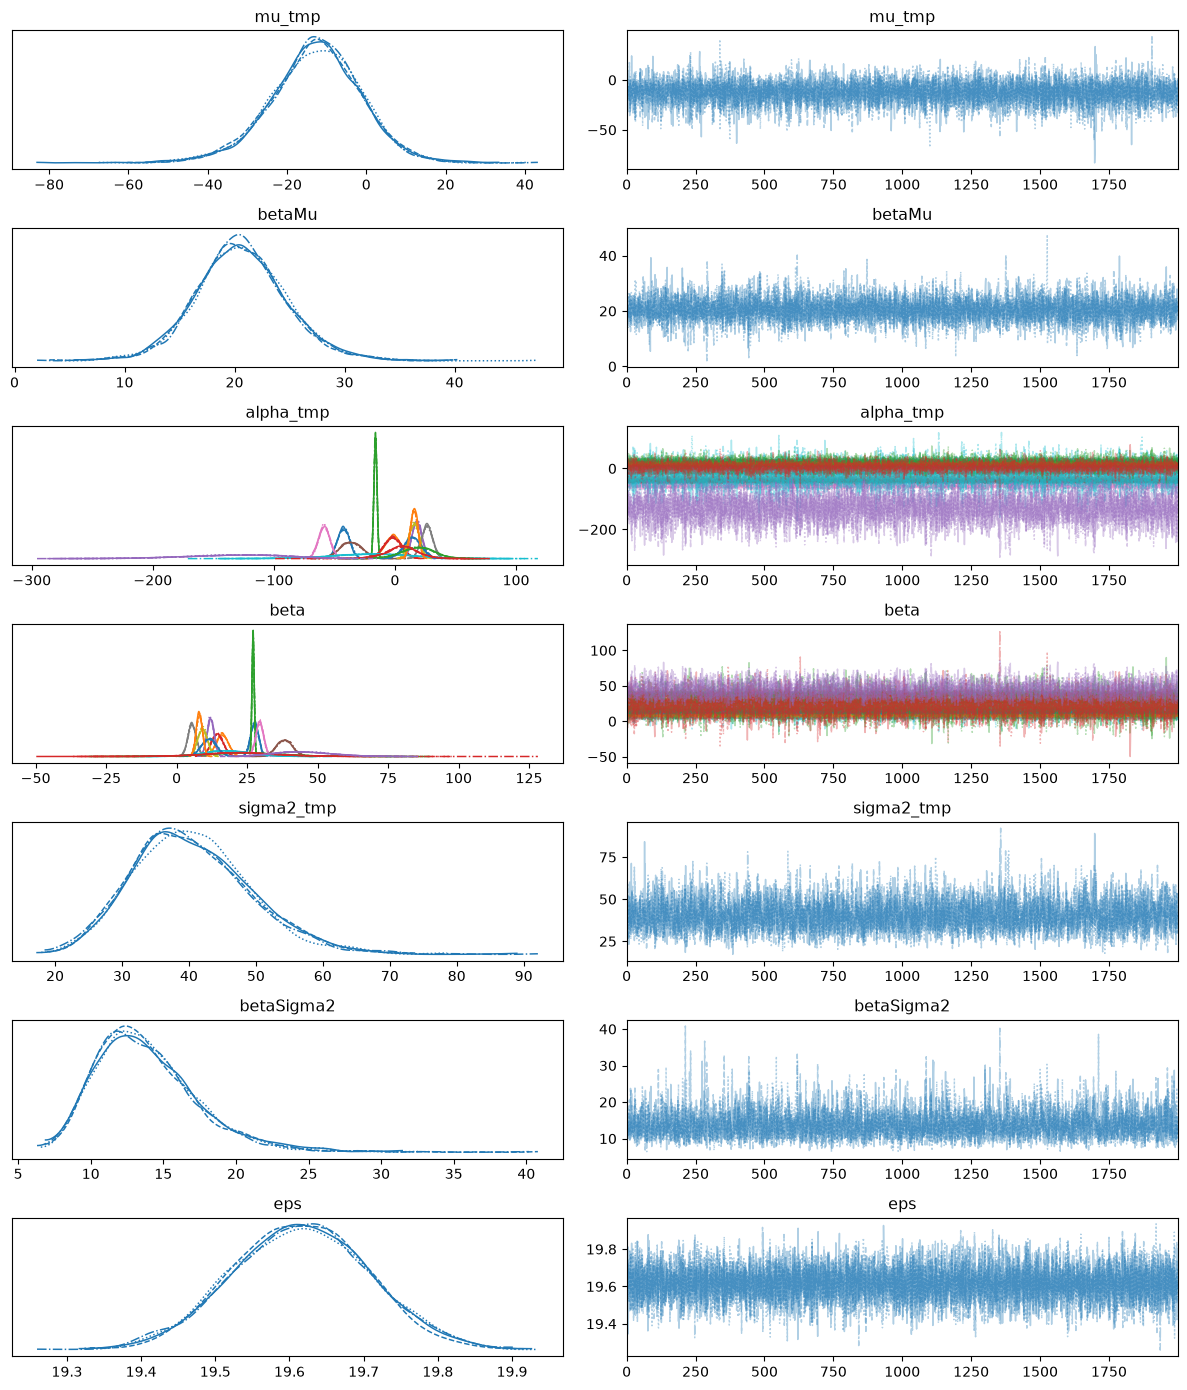

In [37]:
az.plot_trace(hierarchical_trace)
plt.tight_layout()

array([<Axes: title={'center': '94.0% HDI'}>], dtype=object)

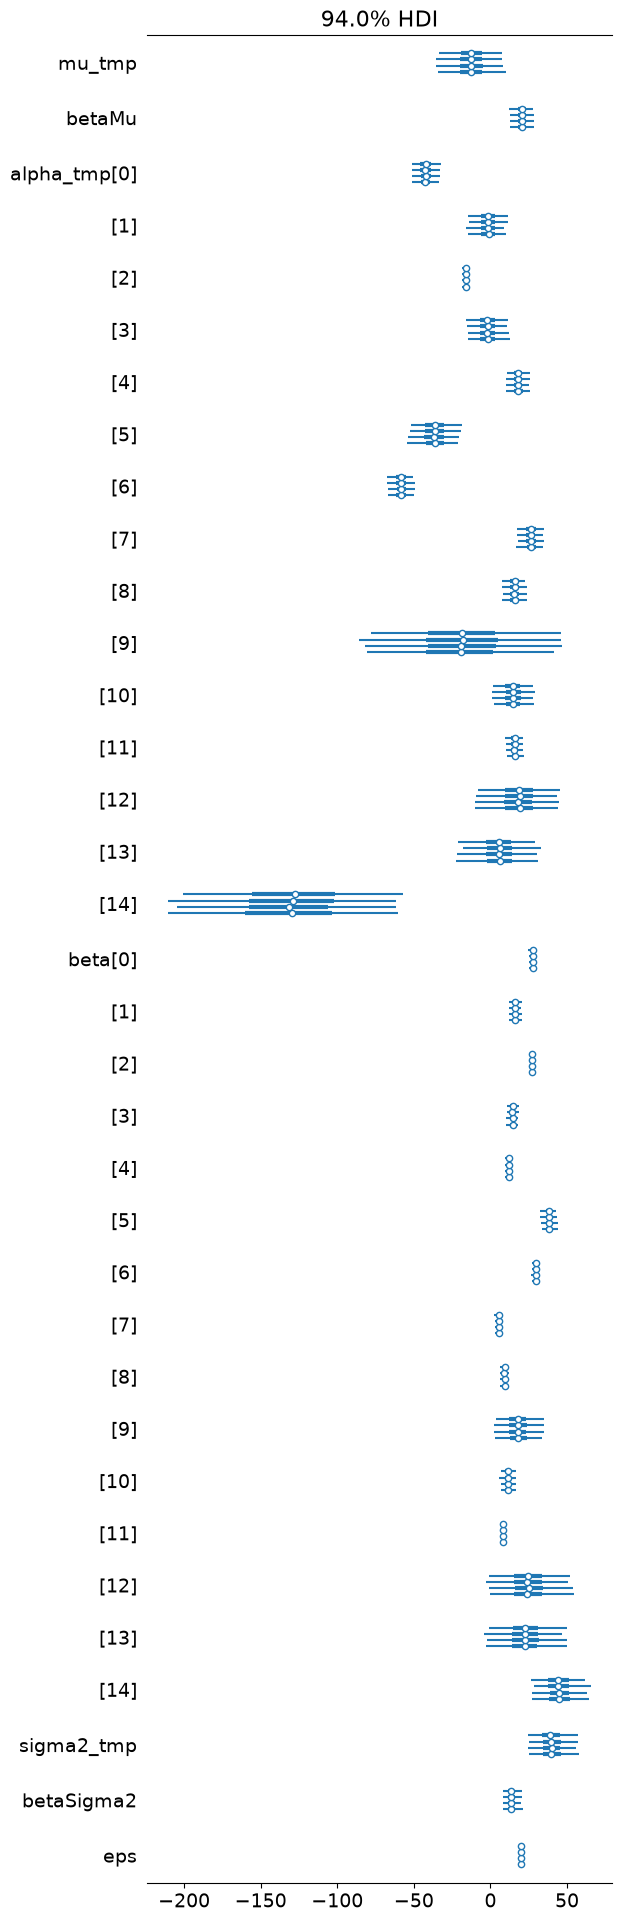

In [40]:
az.plot_forest(hierarchical_trace)

In [42]:
az.summary(hierarchical_trace)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_tmp,-12.805,11.431,-35.215,8.059,0.125,0.174,8635.0,5305.0,1.0
betaMu,20.586,4.169,12.882,28.668,0.047,0.060,8024.0,5699.0,1.0
alpha_tmp[0],-42.356,4.931,-51.692,-33.161,0.058,0.054,7145.0,5574.0,1.0
alpha_tmp[1],-1.519,6.816,-14.149,11.668,0.078,0.077,7581.0,5514.0,1.0
alpha_tmp[2],-16.105,1.253,-18.523,-13.791,0.016,0.014,6355.0,5733.0,1.0
alpha_tmp[3],-1.873,7.154,-15.298,11.786,0.086,0.073,6857.0,5602.0,1.0
alpha_tmp[4],18.091,4.093,10.299,25.668,0.051,0.044,6446.0,5801.0,1.0
alpha_tmp[5],-36.536,9.066,-52.944,-18.989,0.109,0.101,6968.0,5913.0,1.0
alpha_tmp[6],-58.397,4.658,-67.241,-49.596,0.053,0.050,7857.0,6376.0,1.0
alpha_tmp[7],26.455,4.656,17.803,35.225,0.054,0.051,7433.0,5823.0,1.0
